# NexaTel Customer Churn Analytics  Phase 2: Exploratory Data Analysis

This notebook creates 10 simple charts to understand churn patterns, customer usage, network quality, and retention campaign outcomes. Each chart is saved as a PNG image in the `phase2_charts` folder.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT = Path(r"E:\NexaTel-Customer")
CHARTS = PROJECT / "phase2_charts"
CHARTS.mkdir(exist_ok=True)

TABLES = [
    "customers", "plans", "complaints", "usage_data",
    "network_quality", "retention_campaigns"
]

def file_path(name):
    clean = PROJECT / "cleaned_data" / f"{name}_clean.csv"
    root = PROJECT / f"{name}.csv"
    csv_folder = PROJECT / "csv_files" / f"{name}.csv"
    if clean.exists():
        return clean
    if root.exists():
        return root
    return csv_folder

def load(name):
    return pd.read_csv(file_path(name), dtype="string")

customers = load("customers").drop_duplicates("customer_id").copy()
plans = load("plans").drop_duplicates("plan_id").copy()
states = load("states").drop_duplicates("state_id").copy()
complaints = load("complaints")
usage_data = load("usage_data")
network = load("network_quality")
retention = load("retention_campaigns")

# Convert columns used in calculations.
customers["age"] = pd.to_numeric(customers["age"], errors="coerce")
customers["tenure_months"] = pd.to_numeric(customers["tenure_months"], errors="coerce")
plans["monthly_charge"] = pd.to_numeric(plans["monthly_charge"], errors="coerce")
usage_data["data_gb_used"] = pd.to_numeric(usage_data["data_gb_used"], errors="coerce")
network["dropped_call_rate_pct"] = pd.to_numeric(network["dropped_call_rate_pct"], errors="coerce")

customers["churned"] = customers["customer_status"].str.strip().str.lower().eq("churned")
customers["churn_status"] = customers["churned"].map({True: "Churned", False: "Active"})

# Add plan details to customers.
customer_plan = customers.merge(
    states[["state_id", "state_name"]],
    on="state_id", how="left"
).merge(
    plans[["plan_id", "billing_cycle", "monthly_charge"]],
    on="plan_id", how="left"
)

print("Customers:", len(customer_plan))
print("Churn rate:", round(customer_plan["churned"].mean() * 100, 2), "%")
print("Charts will be saved to:", CHARTS)

Customers: 19000
Churn rate: 18.45 %
Charts will be saved to: E:\NexaTel-Customer\phase2_charts


## Chart 1  Overall churn rate
The KPI shows the percentage of customers marked as churned. The bar chart compares the size of the active and churned customer groups.

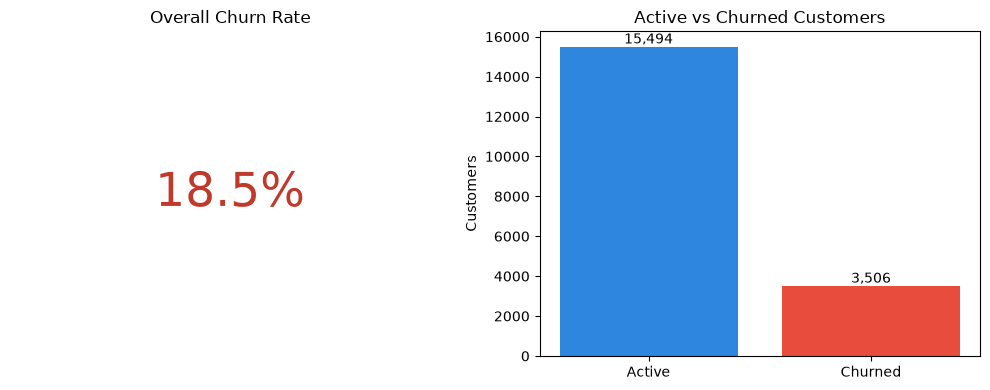

Observation: The overall churn rate is 18.5%. Active customers number 15,494, while churned customers number 3,506.


In [3]:
churn_counts = customer_plan["churn_status"].value_counts().reindex(["Active", "Churned"], fill_value=0)
churn_rate = customer_plan["churned"].mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].text(0.5, 0.5, f"{churn_rate:.1f}%", ha="center", va="center", fontsize=34, color="#c0392b")
axes[0].set_title("Overall Churn Rate")
axes[0].axis("off")
axes[1].bar(churn_counts.index, churn_counts.values, color=["#2e86de", "#e74c3c"])
axes[1].set_title("Active vs Churned Customers")
axes[1].set_ylabel("Customers")
for i, value in enumerate(churn_counts.values): axes[1].text(i, value, f"{value:,}", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(CHARTS / "01_overall_churn_rate.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Observation: The overall churn rate is {churn_rate:.1f}%. Active customers number {churn_counts['Active']:,}, while churned customers number {churn_counts['Churned']:,}.")

## Chart 2  Churn by billing cycle
This chart compares churn rates for Monthly and Annual plans. The higher bar identifies the billing cycle with greater customer loss.

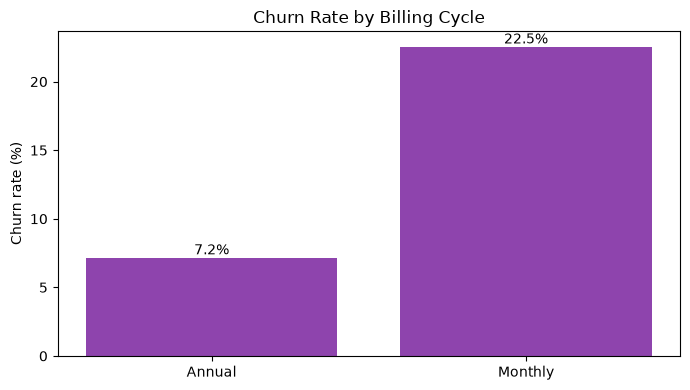

Observation: Annual plans have a 7.2% churn rate across 5,051 customers; Monthly plans have a 22.5% churn rate across 13,949 customers.


In [4]:
cycle = customer_plan.dropna(subset=["billing_cycle"]).groupby("billing_cycle")["churned"].agg(["mean", "count"]).reset_index()
cycle["churn_rate"] = cycle["mean"] * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(cycle["billing_cycle"], cycle["churn_rate"], color="#8e44ad")
ax.set_title("Churn Rate by Billing Cycle")
ax.set_ylabel("Churn rate (%)")
for i, value in enumerate(cycle["churn_rate"]): ax.text(i, value, f"{value:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(CHARTS / "02_churn_by_billing_cycle.png", dpi=150, bbox_inches="tight")
plt.show()
print("Observation: " + "; ".join(f"{r.billing_cycle} plans have a {r.churn_rate:.1f}% churn rate across {int(r['count']):,} customers" for _, r in cycle.iterrows()) + ".")

## Chart 3  Churn by tenure band
Customers are grouped into 0?3 months, 3?12 months, 1?3 years, and 3+ years. This shows whether early-tenure customers are more likely to churn.

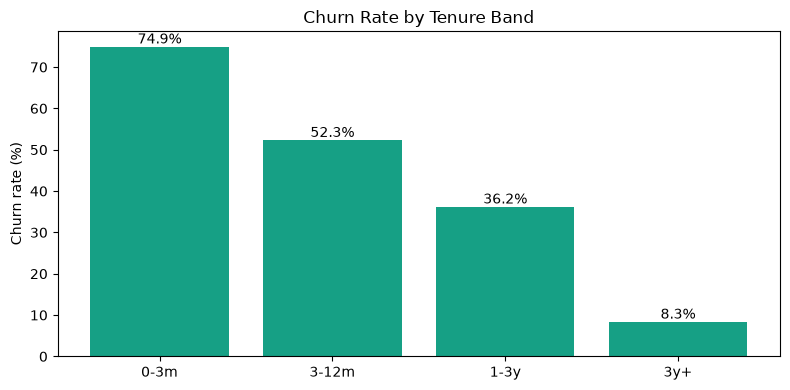

Observation: The 0-3m band has the highest churn rate at 74.9%. The chart helps identify whether churn is concentrated among new or long-tenure customers.


In [5]:
customer_plan["tenure_band"] = pd.cut(customer_plan["tenure_months"], bins=[-1, 3, 12, 36, np.inf], labels=["0-3m", "3-12m", "1-3y", "3y+"])
tenure = customer_plan.groupby("tenure_band", observed=False)["churned"].agg(["mean", "count"]).reset_index()
tenure["churn_rate"] = tenure["mean"] * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(tenure["tenure_band"].astype(str), tenure["churn_rate"], color="#16a085")
ax.set_title("Churn Rate by Tenure Band")
ax.set_ylabel("Churn rate (%)")
for i, value in enumerate(tenure["churn_rate"]): ax.text(i, value, f"{value:.1f}%", ha="center", va="bottom")
plt.tight_layout()
plt.savefig(CHARTS / "03_churn_by_tenure_band.png", dpi=150, bbox_inches="tight")
plt.show()
peak = tenure.loc[tenure["churn_rate"].idxmax()]
print(f"Observation: The {peak['tenure_band']} band has the highest churn rate at {peak['churn_rate']:.1f}%. The chart helps identify whether churn is concentrated among new or long-tenure customers.")

## Chart 4  Churn by number of unresolved complaints
The complaint count is calculated for each customer and joined to the customer status. The chart tests whether unresolved service problems are associated with churn.

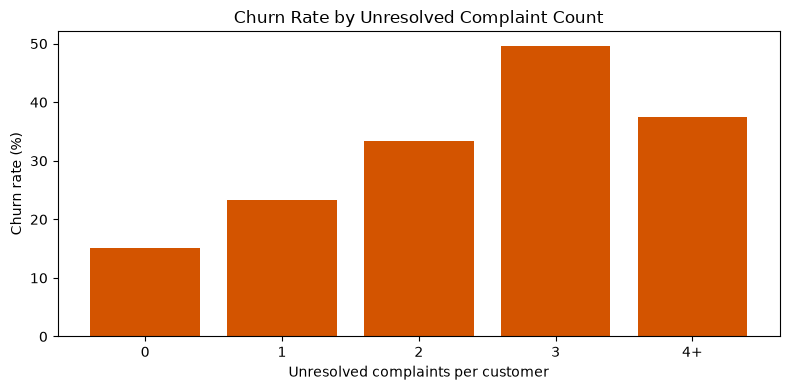

Observation: Customers with 3 unresolved complaints have the highest churn rate at 49.6%, while the 0 group has 15.1%. This comparison indicates whether repeated unresolved complaints are associated with greater churn.


In [6]:
unresolved = complaints[complaints["status"].str.strip().str.lower().eq("unresolved")]
complaint_counts = unresolved.groupby("customer_id").size().rename("unresolved_complaints")
complaint_view = customer_plan[["customer_id", "churned"]].copy().merge(complaint_counts, on="customer_id", how="left").fillna({"unresolved_complaints": 0})
complaint_view["complaint_band"] = complaint_view["unresolved_complaints"].clip(upper=4).astype(int).astype(str)
complaint_view.loc[complaint_view["unresolved_complaints"] >= 4, "complaint_band"] = "4+"
complaint_rate = complaint_view.groupby("complaint_band")["churned"].mean().mul(100).reset_index()
order = ["0", "1", "2", "3", "4+"]
complaint_rate["order"] = complaint_rate["complaint_band"].map({v: i for i, v in enumerate(order)})
complaint_rate = complaint_rate.sort_values("order")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(complaint_rate["complaint_band"], complaint_rate["churned"], color="#d35400")
ax.set_title("Churn Rate by Unresolved Complaint Count")
ax.set_xlabel("Unresolved complaints per customer")
ax.set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.savefig(CHARTS / "04_churn_by_unresolved_complaints.png", dpi=150, bbox_inches="tight")
plt.show()
highest = complaint_rate.loc[complaint_rate["churned"].idxmax()]
lowest = complaint_rate.loc[complaint_rate["churned"].idxmin()]
print(f"Observation: Customers with {highest['complaint_band']} unresolved complaints have the highest churn rate at {highest['churned']:.1f}%, while the {lowest['complaint_band']} group has {lowest['churned']:.1f}%. This comparison indicates whether repeated unresolved complaints are associated with greater churn.")

## Chart 5 Churn by customer segment
The chart compares Mass, Value, Premium, and Enterprise customers. This highlights which commercial segment needs the most retention attention.

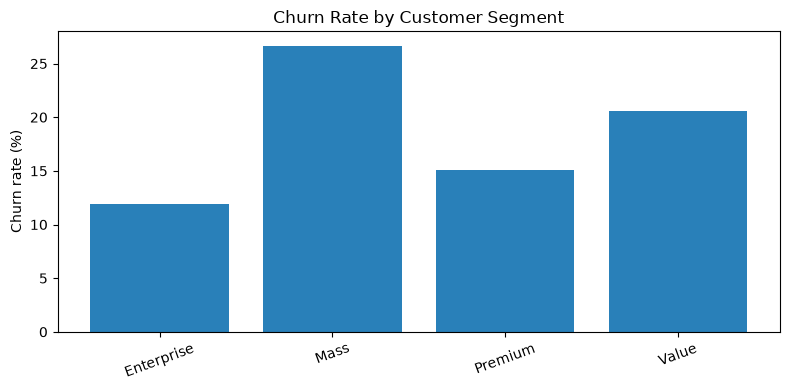

Observation: The Mass segment has the highest churn rate at 26.7%. Segment size is also important when prioritizing retention actions.


In [7]:
segment = customer_plan.groupby("customer_segment")["churned"].agg(["mean", "count"]).reset_index()
segment["churn_rate"] = segment["mean"] * 100
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(segment["customer_segment"], segment["churn_rate"], color="#2980b9")
ax.set_title("Churn Rate by Customer Segment")
ax.set_ylabel("Churn rate (%)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(CHARTS / "05_churn_by_customer_segment.png", dpi=150, bbox_inches="tight")
plt.show()
peak = segment.loc[segment["churn_rate"].idxmax()]
print(f"Observation: The {peak['customer_segment']} segment has the highest churn rate at {peak['churn_rate']:.1f}%. Segment size is also important when prioritizing retention actions.")

## Chart 6 ? Top 10 states by churned customers
This horizontal bar chart ranks states by the number of churned customers, not by churn rate. It identifies the largest geographic sources of churn volume.

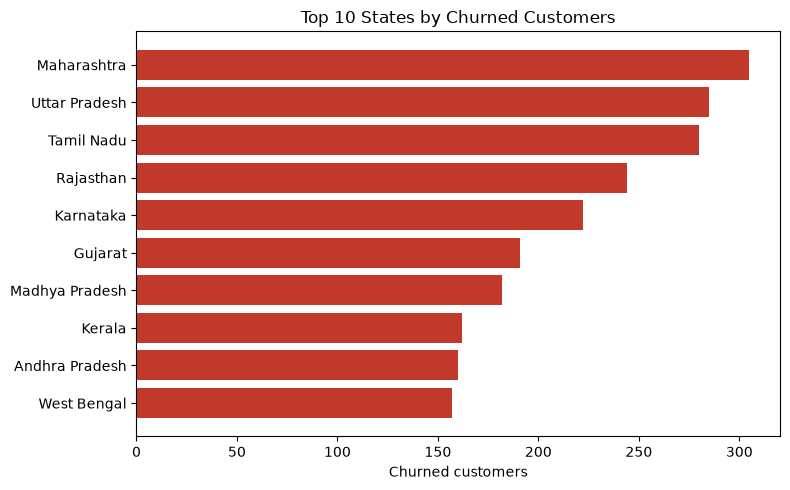

Observation: The leading state by churn volume is Maharashtra with 305 churned customers. These are volume leaders; they may differ from states with the highest churn percentage.


In [8]:
state_churn = customer_plan[customer_plan["churned"]].groupby("state_name").size().sort_values(ascending=False).head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(state_churn.index, state_churn.values, color="#c0392b")
ax.set_title("Top 10 States by Churned Customers")
ax.set_xlabel("Churned customers")
plt.tight_layout()
plt.savefig(CHARTS / "06_top_10_states_by_churn.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Observation: The leading state by churn volume is {state_churn.index[-1]} with {state_churn.iloc[-1]:,} churned customers. These are volume leaders; they may differ from states with the highest churn percentage.")

## Chart 7 Average data usage by city tier
Average monthly data usage is compared across Metro, Tier-2, and Tier-3 cities. This shows how customer usage differs by market type.

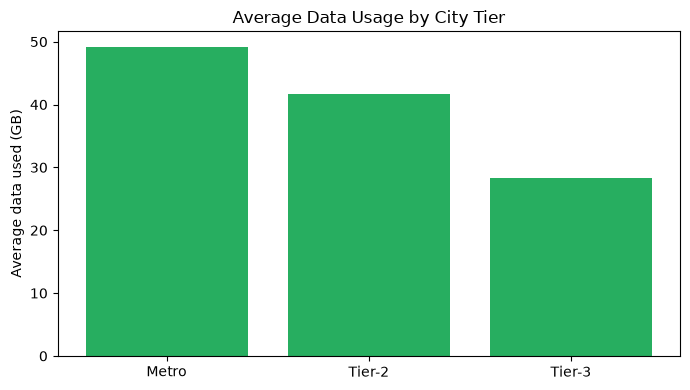

Observation: Metro cities have the highest average data usage at 49.19 GB. The differences can support tier-specific plan and network decisions.


In [9]:
usage = usage_data.merge(customers[["customer_id", "city_tier"]], on="customer_id", how="left")
tier_usage = usage.groupby("city_tier")["data_gb_used"].mean().reindex(["Metro", "Tier-2", "Tier-3"]).dropna()
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(tier_usage.index, tier_usage.values, color="#27ae60")
ax.set_title("Average Data Usage by City Tier")
ax.set_ylabel("Average data used (GB)")
plt.tight_layout()
plt.savefig(CHARTS / "07_average_data_usage_by_city_tier.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Observation: {tier_usage.idxmax()} cities have the highest average data usage at {tier_usage.max():.2f} GB. The differences can support tier-specific plan and network decisions.")

## Chart 8  ARPU distribution
Monthly plan charge is used as a simple ARPU proxy because the available plan table provides monthly charges. The histogram shows how the customer base is distributed across price points.

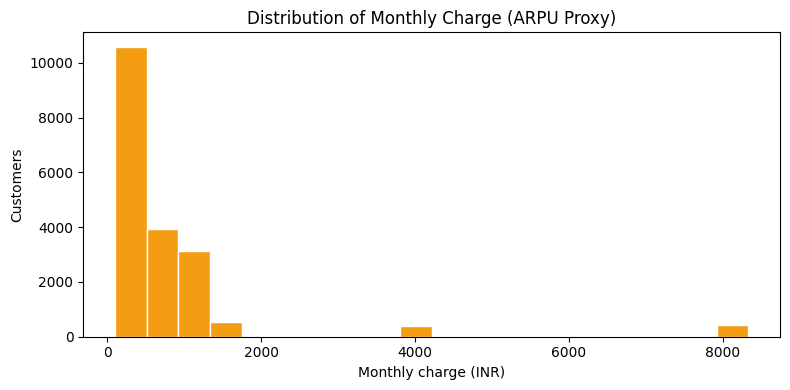

Observation: The median monthly charge is INR 449, while the average is INR 818. The histogram shows whether the base is concentrated in lower-priced plans or spread across premium price points.


In [9]:
arpu = customer_plan["monthly_charge"].dropna()
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(arpu, bins=20, color="#f39c12", edgecolor="white")
ax.set_title("Distribution of Monthly Charge (ARPU Proxy)")
ax.set_xlabel("Monthly charge (INR)")
ax.set_ylabel("Customers")
plt.tight_layout()
plt.savefig(CHARTS / "08_arpu_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Observation: The median monthly charge is INR {arpu.median():,.0f}, while the average is INR {arpu.mean():,.0f}. The histogram shows whether the base is concentrated in lower-priced plans or spread across premium price points.")

## Chart 9  Network quality vs churn
Average dropped-call rate is compared between active and churned customers. This tests whether weaker network experience is associated with churn.

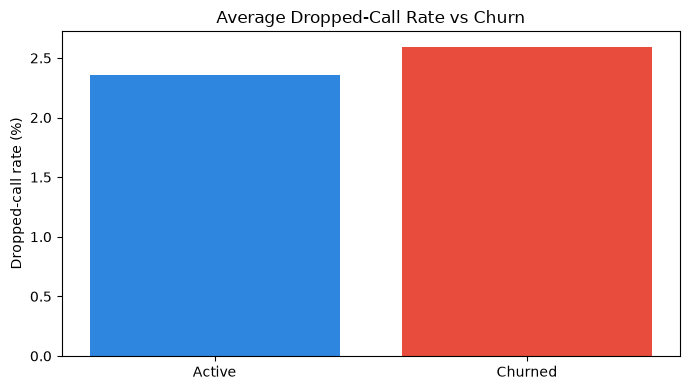

Observation: Active customers average 2.36% dropped calls, compared with 2.59% for churned customers. A higher churned-customer value would support network quality as a retention factor.


In [10]:
network_customer = network.groupby("customer_id")["dropped_call_rate_pct"].mean().rename("avg_dropped_call_rate").reset_index()
network_churn = network_customer.merge(customer_plan[["customer_id", "churn_status"]], on="customer_id", how="left")
network_group = network_churn.groupby("churn_status")["avg_dropped_call_rate"].mean().reindex(["Active", "Churned"])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(network_group.index, network_group.values, color=["#2e86de", "#e74c3c"])
ax.set_title("Average Dropped-Call Rate vs Churn")
ax.set_ylabel("Dropped-call rate (%)")
plt.tight_layout()
plt.savefig(CHARTS / "09_network_quality_vs_churn.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Observation: Active customers average {network_group['Active']:.2f}% dropped calls, compared with {network_group['Churned']:.2f}% for churned customers. A higher churned-customer value would support network quality as a retention factor.")

## Chart 10  Retention campaign outcomes
The first panel counts Accepted, Declined, and No Response outcomes. The second panel shows the retained share for each response category.

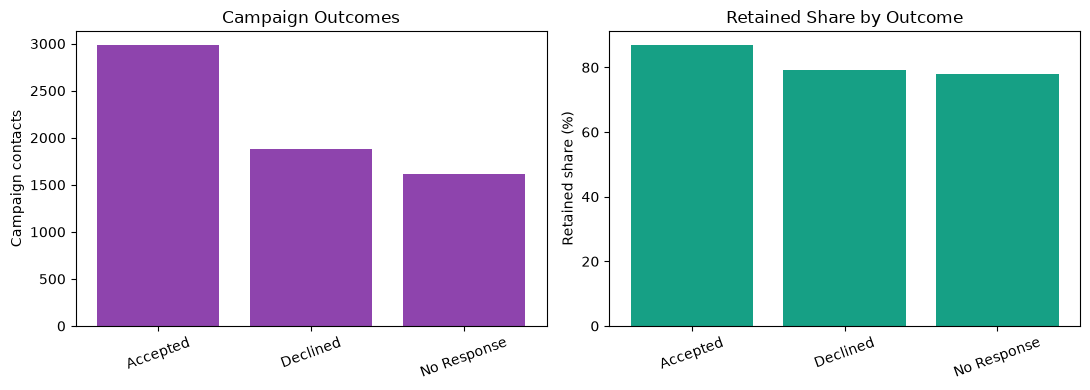

Observation: The outcome chart shows the campaign mix across accepted, declined, and no-response contacts. The retained-share panel shows which response group has the strongest observed retention result; this is descriptive and does not by itself prove campaign causation.


In [11]:
retention["response"] = retention["response"].str.strip().str.title()
retention["retained"] = retention["retained_flag"].str.strip().str.lower().eq("yes")
response_order = ["Accepted", "Declined", "No Response"]
response_counts = retention["response"].value_counts().reindex(response_order, fill_value=0)
retained_share = retention.groupby("response")["retained"].mean().mul(100).reindex(response_order).fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(response_counts.index, response_counts.values, color="#8e44ad")
axes[0].set_title("Campaign Outcomes")
axes[0].set_ylabel("Campaign contacts")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(retained_share.index, retained_share.values, color="#16a085")
axes[1].set_title("Retained Share by Outcome")
axes[1].set_ylabel("Retained share (%)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(CHARTS / "10_retention_campaign_outcomes.png", dpi=150, bbox_inches="tight")
plt.show()
print("Observation: The outcome chart shows the campaign mix across accepted, declined, and no-response contacts. The retained-share panel shows which response group has the strongest observed retention result; this is descriptive and does not by itself prove campaign causation.")

## Phase 2 deliverables

The notebook creates these 10 PNG files in `E:\NexaTel-Customer\phase2_charts`:

1. Overall churn rate
2. Churn by billing cycle
3. Churn by tenure band
4. Churn by unresolved complaints
5. Churn by customer segment
6. Top 10 states by churned customers
7. Average data usage by city tier
8. ARPU distribution
9. Network quality vs churn
10. Retention campaign outcomes